# Mouse Embryo: raw data to spatial domains

This 10x Visium example runs the SpaDOT 1.0.5 workflow from raw counts through
preprocessing, 99 training updates, KMeans domains, and temporal transport
analysis. The raw file is `MouseEmbryo_data/MouseEmbryo.h5ad` beside this notebook.
The feature quota is **3000 / 3000 / 3000 genes per timepoint**,
with fixed final cluster counts **[5, 5, 5]**.

The numeric selection plan beside this notebook asks Python SPARK-X and 12 unlabeled KMeans pseudoregions to select genes directly from raw counts. It contains no saved gene rankings or gene lists.

Install SpaDOT 1.0.5, then run the notebook from `examples/`. Set
`SPADOT_RUN_NAME` to a new name for each run and `SPADOT_DEVICE` to an
available GPU (default `cuda:0`). Start Jupyter with
`PYTHONHASHSEED=2026`, `CUBLAS_WORKSPACE_CONFIG=:4096:8`, and numerical
thread limits of 1. Generated files go under
`examples/runs/<run name>/MouseEmbryo/`; earlier outputs are preserved.


In [1]:
import json
import os
import re
from argparse import Namespace
from importlib.metadata import version as package_version
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

examples = Path.cwd().resolve()
if not (examples / "MouseEmbryo_selection.json").is_file():
    examples = examples / "examples"
if not (examples / "MouseEmbryo_selection.json").is_file():
    raise FileNotFoundError("Run from the repository root or examples/")

import anndata as ad
import numpy as np
import pandas as pd
import torch
import yaml
from threadpoolctl import threadpool_limits
import SpaDOT

installed_version = package_version("SpaDOT")
if installed_version != "1.0.5":
    raise RuntimeError(f"Expected SpaDOT 1.0.5, found {installed_version}")

dataset = "MouseEmbryo"
raw_file = examples / "MouseEmbryo_data" / "MouseEmbryo.h5ad"
selection_file = examples / f"{dataset}_selection.json"
config_file = Path(SpaDOT.__file__).resolve().parent / "config.yaml"
run_name = os.environ.get("SPADOT_RUN_NAME", "raw_python")
if not re.fullmatch(r"[A-Za-z0-9_-]+", run_name):
    raise ValueError("SPADOT_RUN_NAME must contain only letters, numbers, - or _")
output_dir = examples / "runs" / run_name / dataset
output_dir.mkdir(parents=True, exist_ok=True)
device = os.environ.get("SPADOT_DEVICE", "cuda:0")

if not raw_file.is_file():
    raise FileNotFoundError(raw_file)
config = yaml.safe_load(config_file.read_text())
assert config["epoch_start"] == 1
assert config["epoch_stop_exclusive"] == 100
assert config["kl_cycle_epochs"] == 30
assert config["seed"] == 2026
torch.use_deterministic_algorithms(True, warn_only=False)
torch.set_num_threads(1)
torch.set_num_interop_threads(1)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
if device.startswith("cuda"):
    assert torch.cuda.is_available()
    torch.cuda.set_device(int(device.split(":")[1]))
print("SpaDOT version:", installed_version)
print("SpaDOT source:", SpaDOT.__file__)
print("Raw:", raw_file)
print("Output:", output_dir)
print("Device:", device)


/net/mulan/home/wenjinma/projects/SpaDOT/.venv-py39/lib/python3.9/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


/net/mulan/home/wenjinma/projects/SpaDOT/.venv-py39/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SpaDOT version: 1.0.5
SpaDOT source: /net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013_runs/notebook_warningfree_threshold020_20261014/candidate_target/SpaDOT/__init__.py
Raw: /net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/MouseEmbryo_data/MouseEmbryo.h5ad
Output: /net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo
Device: cuda:3


## 1. Preprocess raw counts

Python selects the requested number of SVGs per timepoint from raw counts. The selected union is normalized, log transformed, and scaled separately per timepoint. Raw selected counts remain in `layers["counts"]`.


In [2]:
input_file = output_dir / f"preprocessed_{raw_file.name}"
if input_file.exists():
    raise FileExistsError(f"Input already exists: {input_file}. Choose a new SPADOT_RUN_NAME.")
preprocess_args = Namespace(
    data=str(raw_file), output_dir=str(output_dir),
    prefix="preprocessed_", feature_selection=True,
    n_features="3000,3000,3000", selection_plan=str(selection_file),
)
with threadpool_limits(limits=1):
    SpaDOT.preprocess(preprocess_args)
selection = json.loads((output_dir / "SVG_selection.json").read_text())
assert selection["method"] == "python_sparkx_pseudoregion"
assert list(selection["n_features"].values()) == [3000, 3000, 3000]
prepared = ad.read_h5ad(input_file, backed="r")
prepared_shape = prepared.shape
assert prepared.n_vars == selection["union_genes"]
assert prepared.var_names.tolist() == (output_dir / "SVG_genes.txt").read_text().splitlines()
print("Prepared:", input_file, prepared.shape)
prepared.file.close()


## ===== SPARK-X INPUT INFORMATION ==== 
## number of total samples: 2397
## number of total genes: 20563
## Running with single core, may take some time
## Testing With Projection Kernel


## Testing With Gaussian Kernel 1


## Testing With Gaussian Kernel 2


## Testing With Gaussian Kernel 3


## Testing With Gaussian Kernel 4


...

## Testing With Cosine Kernel 4


## Testing With Cosine Kernel 5


Time taken for mixture kernels: 12.55 seconds


/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013_runs/notebook_warningfree_threshold020_20261014/candidate_target/SpaDOT/utils/_utils.py:375: UserWarning: There are p-values that are exactly 1!
  warnings.warn("There are p-values that are exactly 1!")


Prepared: /net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo/preprocessed_MouseEmbryo.h5ad (8255, 4638)


## 2. Train SpaDOT

The checked-in configuration executes epochs 1 through 99 with a 30-epoch
cyclic SVGP KL weight, seed 2026, and the Python/NumPy OT backend. The latent
file and model are from the **executed epoch 99**. A fresh run directory
prevents overwriting a previous attempt.


In [3]:
latent_file = output_dir / "latent.h5ad"
if latent_file.exists():
    raise FileExistsError(f"Latent already exists: {latent_file}. Choose a new SPADOT_RUN_NAME.")
train_args = Namespace(
    data=str(input_file), output_dir=str(output_dir),
    prefix="", config=str(config_file), save_model=True, device=device,
)
with threadpool_limits(limits=1):
    SpaDOT.train(train_args)
loss = pd.read_csv(output_dir / "loss.csv", index_col=0)
assert [int(epoch) for epoch in loss.index] == list(range(1, 100))
latent = ad.read_h5ad(latent_file, backed="r")
assert latent.shape == (prepared_shape[0], config["z_dim"])
print("Executed epochs:", len(loss), "Latent:", latent.shape)
latent.file.close()


Loading data...


Preparing data...
Calculating spatial graph...


The graph contains 28764 edges, 2397 cells.
12.0000 neighbors per cell on average.
Calculating spatial graph...


The graph contains 27744 edges, 2312 cells.
12.0000 neighbors per cell on average.


Calculating spatial graph...


...

100%|██████████| 99/99 [14:21<00:00,  8.79s/it]

100%|██████████| 99/99 [14:21<00:00,  8.70s/it]

Training finished...
Training time: 861 seconds.


Model saved to /net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo


Executed epochs: 99 Latent: (8255, 20)


## 3. Analyze spatial domains and transitions

The evaluated readout uses KMeans++/Lloyd, seed 2026, `n_init=10`, and
[5, 5, 5] clusters across the timepoints. `SpaDOT.analyze` writes one
spatial-domain image per timepoint and transition dotplots.


In [4]:
timepoints = ['t0', 't1', 't2']
clusters = [5, 5, 5]
analyze_args = Namespace(
    data=str(latent_file), output_dir=str(output_dir), prefix="",
    n_clusters=clusters, seed=2026, n_init=10,
)
with threadpool_limits(limits=1):
    SpaDOT.analyze(analyze_args)
for tp in timepoints:
    assert (output_dir / f"{tp}_domains.png").is_file()
print("Spatial plots:", [str(output_dir / f"{tp}_domains.png") for tp in timepoints])
print("Transition plots:", sorted(str(path) for path in output_dir.glob("transition_dotplot_*.png")))


/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013_runs/notebook_warningfree_threshold020_20261014/candidate_target/SpaDOT/utils/_analyze_utils.py:131: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  latent_cell_sets = adata.obs.groupby('SpaDOT_pred_labels').apply(lambda x: x.index.tolist()).to_dict()


Spatial plots: ['/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo/t0_domains.png', '/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo/t1_domains.png', '/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo/t2_domains.png']
Transition plots: ['/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo/transition_dotplot_0_1.png', '/net/mulan/home/wenjinma/projects/SpaDOT_python_svg_repro_20261013/examples/runs/notebook_exec_105_warnfree_t020_20261014/MouseEmbryo/transition_dotplot_1_2.png']


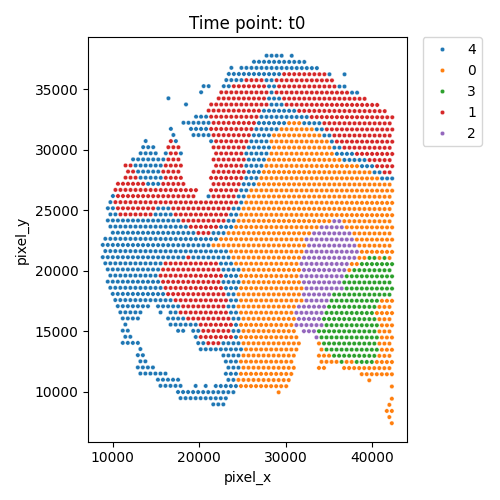

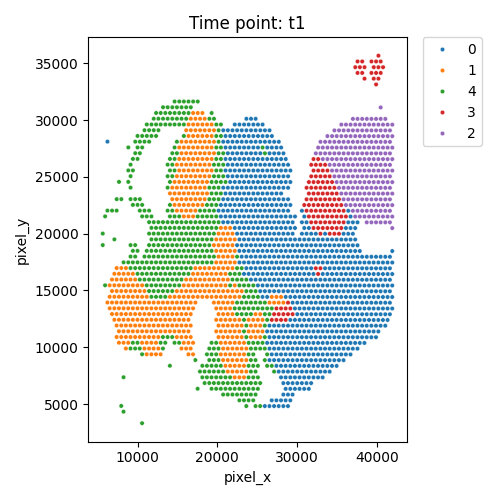

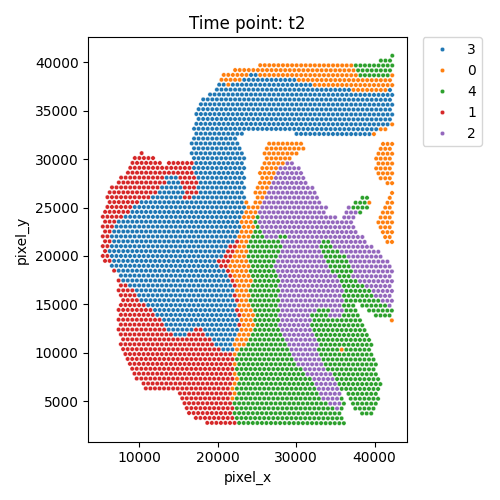

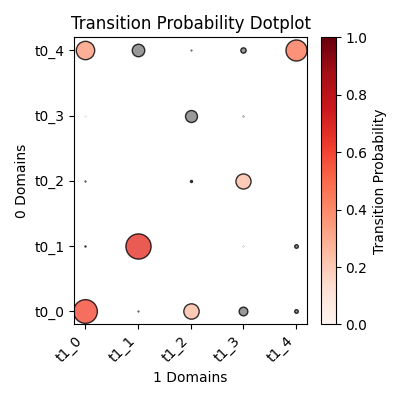

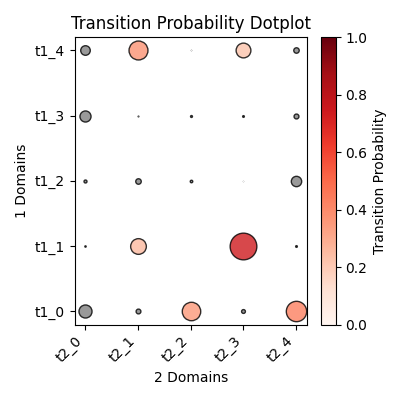

In [5]:
from IPython.display import Image, display

for tp in timepoints:
    display(Image(filename=str(output_dir / f"{tp}_domains.png")))

transition_plots = sorted(output_dir.glob("transition_dotplot_*.png"))
assert len(transition_plots) == len(timepoints) - 1
for plot in transition_plots:
    display(Image(filename=str(plot)))
